# EnergyPulse AI - Notebook 1: Data and Preprocessing

**Goal of the project:** predict the electricity consumption of a meter for every hour, **24 hours in advance**.

This notebook prepares the data. Notebook 2 trains the model and evaluates it.

| Step | What we do |
|---|---|
| 1 | Describe the dataset and explain why we chose it |
| 2 | Check the data quality |
| 3 | Clean the data and turn 15-minute readings into hourly kWh |
| 4 | Choose the meters we work with |
| 5 | Look at the patterns in the data |
| 6 | Split the data by time (train / validation / test) |
| 7 | Build the features without data leakage |
| 8 | Scale the data using the training period only |
| 9 | Check for leakage and save the result |

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

RAW_FILE = Path("../../../LD2011_2014.txt")   # raw UCI file (711 MB). It is not on GitHub, download it from UCI.
DATA_DIR = Path("../data")
DATA_DIR.mkdir(exist_ok=True)

# Time periods (used in step 6)
TRAIN_END = "2013-06-30 23:00"   # train      : 2012-01-01 -> 2013-06-30 (18 months)
VAL_END   = "2013-12-31 23:00"   # validation : 2013-07-01 -> 2013-12-31 (6 months)
                                 # test       : 2014-01-01 -> 2014-12-31 (12 months)
N_METERS = 20      # number of meters we model
SEED = 42          # fixed random seed, so every run gives the same result

## 1. The dataset and why we chose it

**Source:** UCI Machine Learning Repository, *ElectricityLoadDiagrams20112014*
(https://archive.ics.uci.edu/dataset/321/electricityloaddiagrams20112014)

- Real readings from **370 electricity meters** of clients of a Portuguese electricity company.
- One reading **every 15 minutes** from 2011 to 2014. Each value is the average power in **kW** during those 15 minutes.

**Why this dataset fits our project**

1. **Real measured data.** It is not synthetic and not generated by AI.
2. **It is exactly our problem:** the consumption of individual meters over time.
3. **4 years of data.** Every season appears several times, so we can train on the past and test on a full later year.
4. **Very different clients**, from small shops to large factories. We can check that one model works for all of them.
5. **A well-known public dataset** that is often used in research on electricity forecasting, so anyone can repeat our work.

**Limitations (we keep them in mind)**

- There is no list of real faults, so we cannot measure how accurate the alerts are.
- There is no weather data.
- We do not know what type of client each meter is.

In [2]:
raw = pd.read_csv(RAW_FILE, sep=";", decimal=",", index_col=0, parse_dates=True)
raw = raw.astype("float32")          # float32 uses half the memory of float64

print("Rows (one every 15 minutes):", len(raw))
print("Meters (columns)           :", raw.shape[1])
print("From", raw.index.min(), "to", raw.index.max())
raw.iloc[:5, :6]

Rows (one every 15 minutes): 140256
Meters (columns)           : 370
From 2011-01-01 00:15:00 to 2015-01-01 00:00:00


,MT_001,MT_002,MT_003,MT_004,MT_005,MT_006
2011-01-01 00:15:00,0.0,0.0,0.0,0.0,0.0,0.0
2011-01-01 00:30:00,0.0,0.0,0.0,0.0,0.0,0.0
2011-01-01 00:45:00,0.0,0.0,0.0,0.0,0.0,0.0
2011-01-01 01:00:00,0.0,0.0,0.0,0.0,0.0,0.0
2011-01-01 01:15:00,0.0,0.0,0.0,0.0,0.0,0.0


## 2. Data quality checks

In [3]:
expected_rows = len(pd.date_range(raw.index.min(), raw.index.max(), freq="15min"))
quality = pd.Series({
    "missing values"          : int(raw.isna().sum().sum()),
    "negative values"         : int((raw < 0).sum().sum()),
    "duplicated timestamps"   : int(raw.index.duplicated().sum()),
    "missing 15-minute steps" : expected_rows - len(raw),
})
quality

missing values             0
negative values            0
duplicated timestamps      0
missing 15-minute steps    0
dtype: int64

The file has no empty cells, no negative values and no gaps in time.
But **zeros** are a problem: a meter that was not connected yet records 0. Let us count, per year,
how many meters have more than half of their readings equal to 0.

In [4]:
years = raw.loc[:"2014"]
zero_share = (years == 0).groupby(years.index.year).mean()      # share of zeros, per year and meter
(zero_share > 0.5).sum(axis=1).rename("meters with more than 50% zeros")

2011    211
2012     50
2013     33
2014      5
Name: meters with more than 50% zeros, dtype: int64

In 2011 many meters are mostly zeros because they were connected later.
**Decision:** we drop 2011 and use **2012 - 2014** (3 full years).

There is one more problem in the raw file: **daylight saving time** (the clocks in Portugal change twice a year).
- **Last Sunday of March:** the clock jumps from 01:00 to 02:00, so the hour 01:00 - 01:59 does not exist.
  The file still has rows for it with zeros or tiny values -> we mark them as **missing**.
- **Last Sunday of October:** the hour 01:00 - 01:59 happens twice and the file stores the **sum** of both -> we **divide by 2**.

## 3. Cleaning

1. Fix the daylight saving hours.
2. Convert 15-minute **kW** into hourly **kWh**: energy = power x time = kW x 0.25 h, then add the 4 quarters of each hour.
3. Keep 2012 - 2014.
4. Fill the few missing hours (from step 1) with the **same hour of the previous day**. This only uses the past, never the future.

In [5]:
def last_sunday(year, month):
    days = pd.date_range(f"{year}-{month:02d}-01", periods=31, freq="D")
    days = days[(days.month == month) & (days.dayofweek == 6)]
    return days[-1]

def fix_daylight_saving(df):
    df = df.copy()
    for year in sorted(set(df.index.year)):
        for month in (3, 10):
            day = last_sunday(year, month)
            hour = (df.index >= day + pd.Timedelta(hours=1)) & (df.index < day + pd.Timedelta(hours=2))
            if hour.any():
                df.loc[hour] = np.nan if month == 3 else df.loc[hour] / 2
    return df

clean = fix_daylight_saving(raw)

# 15-minute kW -> hourly kWh. An hour is kept only if all 4 quarters exist.
hourly = (clean / 4).resample("1h").sum(min_count=4)
hourly = hourly.loc["2012-01-01 00:00":"2014-12-31 23:00"]

missing_before = int(hourly.isna().sum().sum())
hourly = hourly.fillna(hourly.shift(24))                 # same hour, previous day
hourly = hourly.astype("float64").round(4)

print("Hourly table:", hourly.shape[0], "hours x", hourly.shape[1], "meters")
print("Missing hours filled:", missing_before, "| still missing:", int(hourly.isna().sum().sum()))

Hourly table: 26304 hours x 370 meters
Missing hours filled: 1110 | still missing: 0


## 4. Choosing the meters

We keep only meters whose readings are reliable over 2012 - 2014:

- at most **0.5 %** of the hours are 0, and
- no run of zeros longer than **3 hours** (a longer run means the meter or the connection was down).

From the reliable meters we take **20**. To have small, medium and large clients, we sort the meters by their
average consumption, cut them into 20 groups of similar size, and take one meter at random from each group (seed 42).

This step only uses data quality (zeros). The model never gets any value from it.

In [6]:
def longest_zero_run(values):
    run = best = 0
    for v in values:
        run = run + 1 if v == 0 else 0
        best = max(best, run)
    return best

report = pd.DataFrame({
    "mean_kwh"          : hourly.mean(),
    "zero_share"        : (hourly == 0).mean(),
    "longest_zero_run_h": hourly.apply(lambda s: longest_zero_run(s.values)),
})
report["reliable"] = (report.zero_share <= 0.005) & (report.longest_zero_run_h <= 3)
print("Reliable meters:", int(report.reliable.sum()), "of", len(report))

reliable = report[report.reliable].sort_values("mean_kwh")
groups = pd.qcut(reliable.mean_kwh, N_METERS, labels=False)
rng = np.random.default_rng(SEED)
meters = [rng.choice(g.index.to_numpy()) for _, g in reliable.groupby(groups)]

selected = report.loc[meters, ["mean_kwh", "zero_share", "longest_zero_run_h"]]
selected.round(3)

Reliable meters: 273 of 370


,mean_kwh,zero_share,longest_zero_run_h
MT_007,6.027,0.0,0
MT_016,33.015,0.0,0
MT_042,42.318,0.0,0
MT_051,55.321,0.0,0
MT_304,67.302,0.0,0
MT_237,85.274,0.0,0
MT_315,86.556,0.0,0
MT_356,109.528,0.0,1
MT_138,113.943,0.0,0
MT_243,125.467,0.0,0


In [7]:
hourly = hourly[meters]                                     # from now on: only the 20 meters
hourly.to_csv(DATA_DIR / "hourly_kwh_20_meters.csv")
print("Saved hourly_kwh_20_meters.csv:", hourly.shape)

Saved hourly_kwh_20_meters.csv: (26304, 20)


## 5. Patterns in the data

These plots show why we choose our features in step 7.

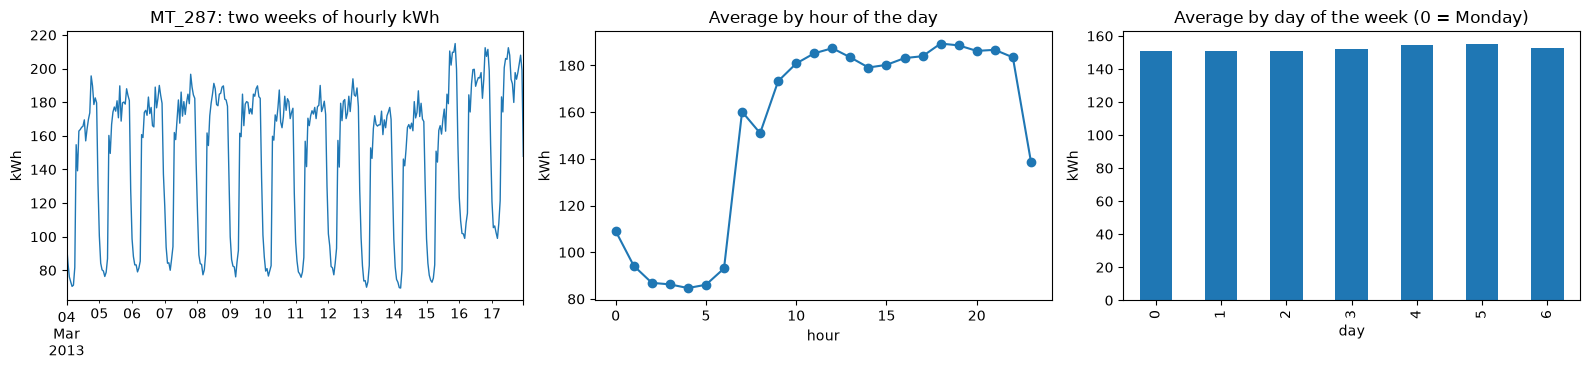

In [8]:
m = "MT_287"     # an example meter (medium size)
y = hourly[m]

fig, ax = plt.subplots(1, 3, figsize=(16, 3.8))
y.loc["2013-03-04":"2013-03-17"].plot(ax=ax[0], lw=1)
ax[0].set_title(f"{m}: two weeks of hourly kWh")
y.groupby(y.index.hour).mean().plot(ax=ax[1], marker="o")
ax[1].set_title("Average by hour of the day"); ax[1].set_xlabel("hour")
y.groupby(y.index.dayofweek).mean().plot(ax=ax[2], kind="bar")
ax[2].set_title("Average by day of the week (0 = Monday)"); ax[2].set_xlabel("day")
for a in ax: a.set_ylabel("kWh")
plt.tight_layout(); plt.show()

- Consumption **repeats every day** (low at night, high during working hours) -> the value **24 hours ago** (and 48 hours ago) is useful.
- For this meter every day of the week has almost the same total. Other meters are different: for example MT_161 uses
  about 9 % less at weekends and MT_016 about 7 % more. So we also give the model the value **one week ago**
  (168 hours) and the **day of the week**.
- **Hour of day** explains a large part of the pattern.
- The level changes slowly during the year (see the plot in step 6) -> **month** and the **average of the previous day** are useful.

## 6. Split the data by time

| Set | Period | Used for |
|---|---|---|
| Train | 2012-01-01 -> 2013-06-30 | fitting the model |
| Validation | 2013-07-01 -> 2013-12-31 | choosing the model settings |
| Test | 2014-01-01 -> 2014-12-31 | the final score, used **once** at the end |

**Why not a random split?** Hours next to each other are almost equal. With a random split the model would see
11:00 and 13:00 in training and be tested on 12:00, so its score would look much better than in real life.
In real life we always predict the **future** from the **past**, so we split by time and never shuffle.

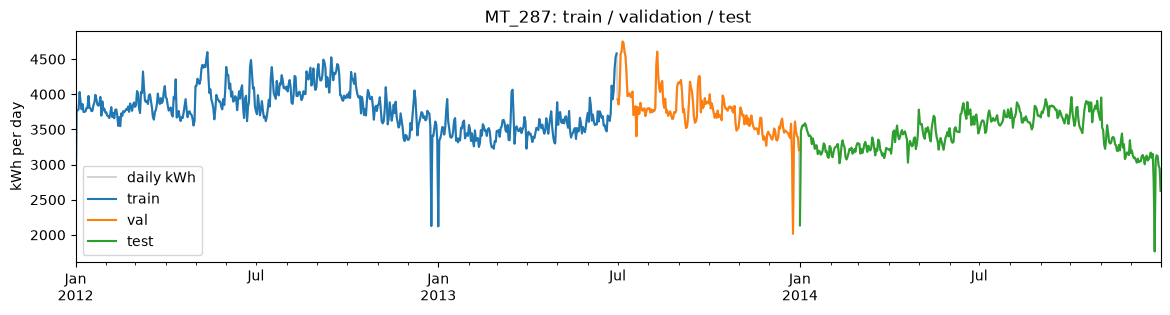

In [9]:
def which_set(timestamps):
    return np.where(timestamps <= pd.Timestamp(TRAIN_END), "train",
           np.where(timestamps <= pd.Timestamp(VAL_END), "val", "test"))

ax = y.resample("D").sum().plot(figsize=(14, 3), color="lightgray", label="daily kWh")
for name, color in [("train", "tab:blue"), ("val", "tab:orange"), ("test", "tab:green")]:
    daily = y.resample("D").sum()
    daily[which_set(daily.index) == name].plot(ax=ax, color=color, label=name)
ax.set_title(f"{m}: train / validation / test"); ax.set_ylabel("kWh per day"); ax.legend(); plt.show()

## 7. Features (no data leakage)

We predict the consumption of hour **t**, and we make the prediction **24 hours before**.
So every feature may only use data that is **at least 24 hours old**.

| Feature | Meaning | Why |
|---|---|---|
| `lag_24` | consumption at the same hour **yesterday** | daily pattern |
| `lag_48` | consumption at the same hour **2 days ago** | daily pattern, second look |
| `lag_168` | consumption at the same hour **last week** | weekly pattern (weekend vs weekday) |
| `mean_prev_day` | average of the 24 hours that end 24 hours before t | current level of the meter |
| `hour` | hour of the day (0 - 23) | known in advance |
| `dayofweek` | day of the week (0 = Monday) | known in advance |
| `month` | month (1 - 12) | season, known in advance |

The first week of 2012 has no `lag_168`, so those rows are dropped.

In [10]:
FEATURES = ["lag_24", "lag_48", "lag_168", "mean_prev_day", "hour", "dayofweek", "month"]
KWH_COLUMNS = ["y", "lag_24", "lag_48", "lag_168", "mean_prev_day"]    # columns measured in kWh

def build_features(y):
    df = pd.DataFrame({"y": y})                         # y = the value we want to predict
    df["lag_24"]  = y.shift(24)
    df["lag_48"]  = y.shift(48)
    df["lag_168"] = y.shift(168)
    df["mean_prev_day"] = y.shift(24).rolling(24).mean()   # newest value used: t-24
    df["hour"]      = df.index.hour
    df["dayofweek"] = df.index.dayofweek
    df["month"]     = df.index.month
    return df.dropna()

build_features(hourly[m]).head()

,y,lag_24,lag_48,lag_168,mean_prev_day,hour,dayofweek,month
2012-01-08 00:00:00,107.8543,99.7244,103.6639,87.6575,162.077900,0,6,1
2012-01-08 01:00:00,88.4006,87.6599,89.8745,83.9665,161.985625,1,6,1
2012-01-08 02:00:00,81.9980,81.9980,84.2126,82.2441,161.893350,2,6,1
2012-01-08 03:00:00,82.7362,80.0295,84.7047,81.9980,161.698550,3,6,1
2012-01-08 04:00:00,80.5217,80.0271,84.2126,84.7047,161.524154,4,6,1


## 8. Scaling (fitted on the training period only)

The meters are very different in size: the smallest uses about 6 kWh per hour, the largest about 2,500.
We want **one model for all 20 meters**, so we put them on the same scale:

**scaled value = kWh / average kWh of this meter in the training period**

After scaling, every meter has values around 1.0. The average is computed **only from the training period**
(2012-01-01 -> 2013-06-30). Validation and test data are never used to compute it, so no information
from the future leaks into the training data. Calendar features (hour, day, month) are not scaled.

In [11]:
parts = []
for meter in meters:
    df = build_features(hourly[meter])
    scale = hourly[meter].loc[:TRAIN_END].mean()          # training period only
    df["kwh"] = df["y"]                                    # keep the real kWh for the evaluation
    df[KWH_COLUMNS] = df[KWH_COLUMNS] / scale
    df.insert(0, "meter", meter)
    df["scale"] = scale
    df["set"] = which_set(df.index)
    parts.append(df)

data = pd.concat(parts)
data.index.name = "timestamp"
data.groupby("meter")[["kwh", "scale", "y"]].mean().round(2).head()

,kwh,scale,y
meter,,,
MT_007,6.04,4.47,1.35
MT_016,32.97,32.51,1.01
MT_042,42.25,40.69,1.04
MT_051,55.30,53.96,1.02
MT_098,681.44,671.51,1.01


## 9. Leakage check and save

In [12]:
periods = data.reset_index().groupby("set").timestamp.agg(["min", "max", "count"]).loc[["train", "val", "test"]]
assert periods.loc["train", "max"] < periods.loc["val", "min"], "train and validation overlap"
assert periods.loc["val", "max"] < periods.loc["test", "min"], "validation and test overlap"

y = hourly[m]
t = pd.Timestamp("2013-09-10 15:00")
changed = y.copy()
changed.loc[t - pd.Timedelta(hours=23):t] *= 10
same = build_features(y).loc[t, FEATURES].equals(build_features(changed).loc[t, FEATURES])
assert same, "a feature uses data newer than 24 hours"
print("OK: features of", t, "do not change when the last 23 hours change")

periods.rename(columns={"min": "from", "max": "to", "count": "rows"})

OK: features of 2013-09-10 15:00:00 do not change when the last 23 hours change


,from,to,rows
set,,,
train,2012-01-08,2013-06-30 23:00:00,259200
val,2013-07-01,2013-12-31 23:00:00,88320
test,2014-01-01,2014-12-31 23:00:00,175200


In [13]:
data.round(6).to_csv(DATA_DIR / "features.csv.gz")
print("Saved features.csv.gz:", data.shape)

Saved features.csv.gz: (522720, 12)


## Summary

| Requirement | What we did |
|---|---|
| Dataset quality and justification | Real UCI meter data (370 meters, 2011-2014). Checked missing, negative, duplicated values and gaps. Dropped 2011 (meters not connected yet), fixed daylight saving hours, kept 20 reliable meters of different sizes. |
| Preprocessing | 15-minute kW -> hourly kWh, 7 simple features, scaling per meter. |
| No data leakage | Split by time (no shuffle). Every feature is at least 24 hours old (tested above). The scaling average uses the training period only. The test year is not used until the final evaluation in Notebook 2. |

**Next:** `02_model_training_evaluation.ipynb`